#导入数据

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 
df = pd.read_csv('D:/Learning/Pandas/Date/train.csv')
df.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


#船上人员基本情况

In [2]:
print('性别分布情况：')
print(df.Sex.value_counts())
print('\n年龄分布情况:')
print(df.Age.value_counts())
print('\n舱等级分布情况:')
print(df.Pclass.value_counts())
print('\n登录港口分布情况:')
print(df.Embarked.value_counts())
combo = df.groupby(['Pclass', 'Sex', 'Embarked']).size().sort_values(ascending=False)
print("\n最常见组合 (Pclass, Sex, Embarked) 及人数:")
print(combo.head(5))

性别分布情况：
Sex
male      577
female    314
Name: count, dtype: int64

年龄分布情况:
Age
24.00    30
22.00    27
18.00    26
28.00    25
19.00    25
         ..
24.50     1
0.67      1
0.42      1
34.50     1
74.00     1
Name: count, Length: 88, dtype: int64

舱等级分布情况:
Pclass
3    491
1    216
2    184
Name: count, dtype: int64

登录港口分布情况:
Embarked
S    644
C    168
Q     77
Name: count, dtype: int64

最常见组合 (Pclass, Sex, Embarked) 及人数:
Pclass  Sex     Embarked
3       male    S           265
2       male    S            97
3       female  S            88
1       male    S            79
2       female  S            67
dtype: int64


#全体及不同性别生存率


In [3]:
overall_survival_rate = df['Survived'].mean()
print(f'全体生存率为：{overall_survival_rate:.2%}')
sex_survial_rate = df.groupby('Sex')['Survived'].mean()
print('不同性别生存率为：',sex_survial_rate)
print(f'女性生存率是男性的{sex_survial_rate['female']/sex_survial_rate['male']:.2f}倍')


全体生存率为：38.38%
不同性别生存率为： Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64
女性生存率是男性的3.93倍


#同舱同性别乘客年龄中位数补充缺失值

In [4]:
print("缺失值数量:", df['Age'].isnull().sum())
print('年龄中位数：',df.groupby(['Pclass','Sex'])['Age'].median())
df['Age'] = df.groupby(['Pclass', 'Sex'])['Age'].transform(lambda x: x.fillna(x.median()))
print("填充后缺失值数量:", df['Age'].isnull().sum())

缺失值数量: 177
年龄中位数： Pclass  Sex   
1       female    35.0
        male      40.0
2       female    28.0
        male      30.0
3       female    21.5
        male      25.0
Name: Age, dtype: float64
填充后缺失值数量: 0


transform()可以对每个分组进行操作，返回一个与原始数据相同长度，相同索引，相同数据的Series。
apply不能将数据索引对齐，返回值可能与原始数据长度不同，或者含有缺失值。

#不同头衔乘客的生存率

In [5]:
df['Title'] = df['Name'].str.extract(' ([A-Za-z]+)\.',expand = False)
print('头衔分布情况：')
print(df['Title'].value_counts())

头衔分布情况：
Title
Mr          517
Miss        182
Mrs         125
Master       40
Dr            7
Rev           6
Major         2
Mlle          2
Col           2
Don           1
Mme           1
Ms            1
Lady          1
Sir           1
Capt          1
Countess      1
Jonkheer      1
Name: count, dtype: int64


<>:1: SyntaxWarning: invalid escape sequence '\.'
<>:1: SyntaxWarning: invalid escape sequence '\.'
C:\Users\m1553\AppData\Local\Temp\ipykernel_24344\1916806313.py:1: SyntaxWarning: invalid escape sequence '\.'
  df['Title'] = df['Name'].str.extract(' ([A-Za-z]+)\.',expand = False)


将头衔简化：

In [6]:
#def
def update_title(title):
    common_titles = ['Mr', 'Miss', 'Mrs', 'Master']
    if title in common_titles:
        return title
    else:
        return 'Other'

df['Title'] = df['Title'].apply(update_title)
print('更新后头衔分布情况：')
print(df['Title'].value_counts())


更新后头衔分布情况：
Title
Mr        517
Miss      182
Mrs       125
Master     40
Other      27
Name: count, dtype: int64


In [7]:
#lambda
common_titles = ['Mr', 'Miss', 'Mrs', 'Master']
df['Title'] = df['Title'].apply(lambda x: x if x in common_titles else 'Other')
print('更新后头衔分布情况：')
print(df['Title'].value_counts())

更新后头衔分布情况：
Title
Mr        517
Miss      182
Mrs       125
Master     40
Other      27
Name: count, dtype: int64


#不同头衔乘客的生存率

In [8]:
title_survival = df.groupby('Title')['Survived'].mean().sort_values(ascending=False)
print('各头衔的生存率：')
print(title_survival)


各头衔的生存率：
Title
Mrs       0.792000
Miss      0.697802
Master    0.575000
Other     0.444444
Mr        0.156673
Name: Survived, dtype: float64


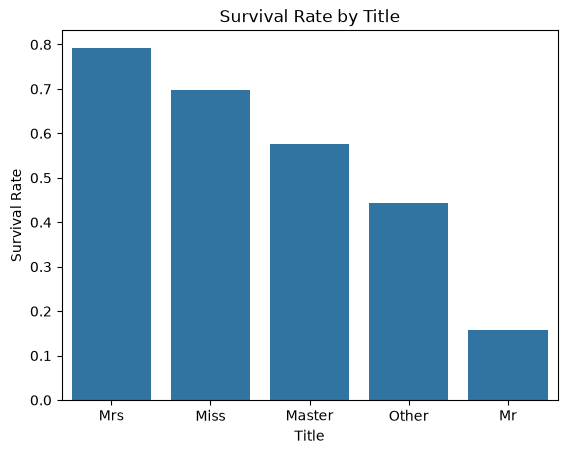

In [9]:
#可视化处理
sns.barplot(x=title_survival.index, y=title_survival.values)
plt.title('Survival Rate by Title')
plt.ylabel('Survival Rate')
plt.show()

#家庭大小与存活率的关系

In [19]:
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
def Familytype(size):
    if size == 1:
        return 'Single'
    elif size <= 4:
        return 'Small'
    else:
        return 'Large'

df['FamilyType'] = df['FamilySize'].apply(Familytype)
print('家庭类型分布情况：')
print(df['FamilyType'].value_counts())
print('\n家庭类型生存率:')
pivot = df.pivot_table(values='Survived', 
                       index='Pclass', 
                       columns='FamilyType', 
                       aggfunc='mean')
print(pivot)


家庭类型分布情况：
FamilyType
Single    537
Small     292
Large      62
Name: count, dtype: int64

家庭类型生存率:
FamilyType     Large    Single     Small
Pclass                                  
1           0.666667  0.532110  0.732673
2           1.000000  0.346154  0.628205
3           0.074074  0.212963  0.407080
